In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from AI.strict_paper_simulation.strict_full_orbit_simulation import N_PARTICLES

DATA_FILE = Path("./data/ml_dataset/ml_dataset.npz")
data = np.load(DATA_FILE)
psi_history = data["psi"]

print("psi shape =", psi_history.shape)
print("psi dtype =", psi_history.dtype)

psi shape = (100001, 2000)
psi dtype = float32


In [3]:
# ==========================================
# Phase-unwrapping diagnostics
# ==========================================
# 我们没必要保存完整的 unwrapped phase. 只要分小块计算，然后提取每个粒子的统计量即可
N_PARTICLES = psi_history.shape[1]

CHUNK_SIZE = 100

phase_span_turns = np.empty(N_PARTICLES, dtype=np.float32)
net_phase_turns = np.empty(N_PARTICLES, dtype=np.float32)

for start in range(0, N_PARTICLES, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, N_PARTICLES)
    psi_chunk = psi_history[:, start:end].astype(np.float64)
    psi_unwrapped = np.unwrap(psi_chunk, axis=0)
    # Total phase range
    phase_span=(np.max(psi_unwrapped,axis=0) - np.min(psi_unwrapped,axis=0))
    # Convert radians -> number of 2pi turns
    phase_span_turns[start:end] = (phase_span / (2.0 * np.pi))
    # Net phase displacement
    # -1代表最后一个时间步，0代表第一个时间步
    net_phase_turns[start:end] = (np.abs(psi_unwrapped[-1] - psi_unwrapped[0]) / (2.0 * np.pi))

print(
    "phase span turns:",
    phase_span_turns.min(),
    phase_span_turns.max()
)
print(
    "net phase turns:",
    net_phase_turns.min(),
    net_phase_turns.max()
)

phase span turns: 0.023740595 64.04869
net phase turns: 7.365458e-05 64.04869


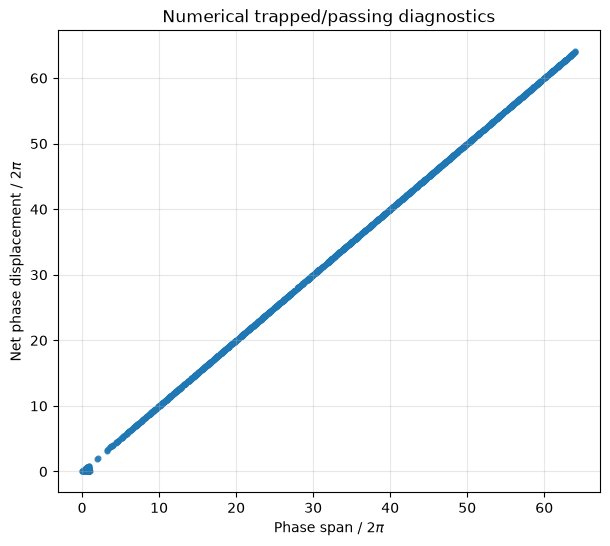

In [4]:
plt.figure(figsize=(7,6))
plt.scatter(phase_span_turns, net_phase_turns, s=12, alpha=0.7)
plt.xlabel(r"Phase span / $2\pi$")
plt.ylabel(r"Net phase displacement / $2\pi$")
plt.title("Numerical trapped/passing diagnostics")
plt.grid(alpha=0.3)
plt.show()

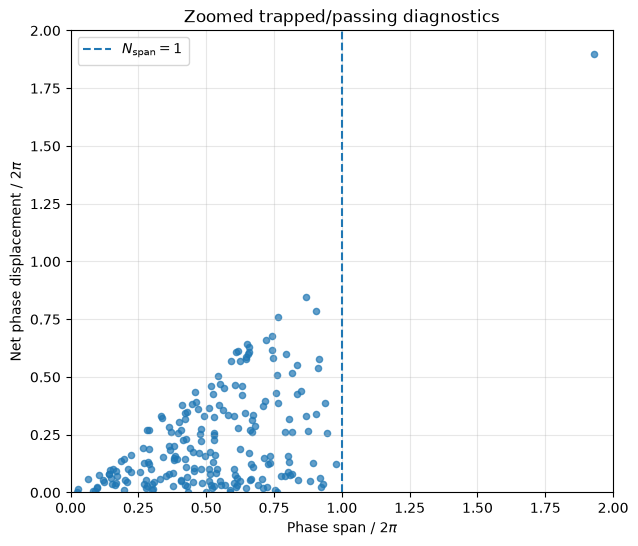

In [5]:
# trapped / near-separatrix 区域
plt.figure(figsize=(7, 6))
plt.scatter(phase_span_turns, net_phase_turns, s=20, alpha=0.7)
plt.xlim(0, 2.0)
plt.ylim(0, 2.0)
plt.axvline(1.0, linestyle="--", label=r"$N_{\rm span}=1$")
plt.xlabel(r"Phase span / $2\pi$")
plt.ylabel(r"Net phase displacement / $2\pi$")
plt.title("Zoomed trapped/passing diagnostics")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [6]:
# ==========================================
# Generate trapped / passing labels
# ==========================================
# 制作trap和passing标签
labels = np.zeros(N_PARTICLES, dtype=np.int8)
labels[phase_span_turns < 1.0] = 1 # trapped定义为1
n_trapped = np.sum(labels == 1)
n_passing = np.sum(labels == 0)
print("Total particles =", N_PARTICLES)
print("Trapped =", n_trapped)
print("Passing =", n_passing)

print("Trapped ratio =", n_trapped / N_PARTICLES)
print("Passing ratio =", n_passing / N_PARTICLES)

Total particles = 2000
Trapped = 212
Passing = 1788
Trapped ratio = 0.106
Passing ratio = 0.894


In [7]:
# ==========================================
# Sanity check near the labeling boundary
# ==========================================
trapped_indices = np.where(labels == 1)[0]
passing_indices = np.where(labels == 0)[0]

# 接下来取出分界线处的粒子
# trapped 中 phase_span 最大的 10 个
near_boundary_trapped = trapped_indices[
    np.argsort(
        phase_span_turns[trapped_indices]
    )[-10:]
]

# passing 中 phase_span 最小的 10 个
near_boundary_passing = passing_indices[
    np.argsort(
        phase_span_turns[passing_indices]
    )[:10]
]

print("Near-boundary trapped particles:")

for particle_id in near_boundary_trapped:
    print(
        f"id = {particle_id:4d}, "
        f"span = {phase_span_turns[particle_id]:.6f}, "
        f"net = {net_phase_turns[particle_id]:.6f}"
    )

print()
print("Near-boundary passing particles:")
for particle_id in near_boundary_passing:
    print(
        f"id = {particle_id:4d}, "
        f"span = {phase_span_turns[particle_id]:.6f}, "
        f"net = {net_phase_turns[particle_id]:.6f}"
    )

Near-boundary trapped particles:
id = 1755, span = 0.904653, net = 0.341014
id =  983, span = 0.905627, net = 0.786721
id =  671, span = 0.910642, net = 0.540251
id = 1264, span = 0.917370, net = 0.577006
id = 1738, span = 0.919824, net = 0.061439
id =  621, span = 0.924695, net = 0.023652
id = 1365, span = 0.929523, net = 0.037627
id = 1461, span = 0.936275, net = 0.388842
id =  923, span = 0.944305, net = 0.256606
id = 1226, span = 0.978104, net = 0.124455

Near-boundary passing particles:
id =  323, span = 1.928023, net = 1.900102
id = 1686, span = 2.024124, net = 2.004135
id = 1569, span = 3.175366, net = 3.175366
id =  277, span = 3.254441, net = 3.254441
id = 1032, span = 3.385373, net = 3.385373
id =  496, span = 3.661744, net = 3.661744
id =  839, span = 3.675106, net = 3.675106
id = 1922, span = 3.813560, net = 3.813560
id = 1969, span = 3.895058, net = 3.866073
id = 1936, span = 3.913096, net = 3.913096


In [8]:
from sklearn.model_selection import train_test_split
# ==========================================
# Stratified train / validation / test split
# ==========================================

particle_indices = np.arange(N_PARTICLES)

# First split:
# 70% train, 30% temporary
# 如果不写stratify=labels, 则表示不考虑标签的分布, 只是随机分割。随机切分之后，可能出现某个集合里 trapped 太少，甚至比例偏得比较明显。
train_indices, temp_indices = train_test_split(particle_indices,test_size=0.30, random_state=42, stratify=labels)

# Split the remaining 30% equally:
# 15% validation, 15% test
# 这一次切分的对象已经不是全部 2000 个粒子了，而只是temp_indices对应的那 600 个粒子
# 所以要告诉程序：请按照这 600 个粒子自己的 label 进行分层
val_indices, test_indices = train_test_split(temp_indices, test_size=0.50, random_state=42, stratify=labels[temp_indices])

def print_split_info(name, indices):
    split_labels = labels[indices]

    n_total = len(indices)
    n_trapped = np.sum(split_labels == 1)
    n_passing = np.sum(split_labels == 0)

    print(name)
    print("  total   =", n_total)
    print("  trapped =", n_trapped)
    print("  passing =", n_passing)
    print(
        "  trapped ratio =",
        n_trapped / n_total
    )
    print()


print_split_info(
    "Train",
    train_indices
)

print_split_info(
    "Validation",
    val_indices
)

print_split_info(
    "Test",
    test_indices
)

Train
  total   = 1400
  trapped = 148
  passing = 1252
  trapped ratio = 0.10571428571428572

Validation
  total   = 300
  trapped = 32
  passing = 268
  trapped ratio = 0.10666666666666667

Test
  total   = 300
  trapped = 32
  passing = 268
  trapped ratio = 0.10666666666666667



In [9]:
# 把标签和划分结果保存下来
LABEL_FILE = DATA_FILE.parent / "labels_and_split.npz"

np.savez(
    LABEL_FILE,

    labels=labels,

    phase_span_turns=phase_span_turns,
    net_phase_turns=net_phase_turns,

    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,

    trapped_threshold=1.0
)

print("Saved to:", LABEL_FILE)

Saved to: data/ml_dataset/labels_and_split.npz
